In [1]:
!pip install -q nltk pandas requests
import pandas as pd
import re
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully!


In [2]:
import requests
import zipfile
import io
import glob
import os

repo_url = (
    "https://api.github.com/repos/"
    "WuraolaOyewusi/"
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing"
)

response = requests.get(repo_url)
response.raise_for_status()

branch = response.json()["default_branch"]

zip_url = (
    "https://codeload.github.com/"
    "WuraolaOyewusi/"
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing/"
    f"zip/refs/heads/{branch}"
)

response = requests.get(zip_url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall("/content/healthcare_data")

files = glob.glob(
    "/content/healthcare_data/**/*.csv",
    recursive=True
)

if not files:
    raise FileNotFoundError("No CSV dataset found in the repository.")

df = pd.read_csv(files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (1626, 4)
Columns: ['Date', 'Source', 'Headlines', 'Teaser']


,Date,Source,Headlines,Teaser
0,October 2002,Medscape Nurses,Monthly Summaries of Nursing Research,"Menopause, pain management, exercise, family c..."
1,October 2002,Medscape Neurology,Reports From the 56th Annual Meeting of the AA...,Learn about new therapies for the physical com...
2,September 2002,Medscape Nurses,NINR -- September 2002,"Exercise, exercise! Good for those with HIV, a..."
3,July 2002,Medscape Nurses,Monthly Summaries of Nursing Research,Review new nursing research on cancer and depr...
4,March 2002,Medscape Nurses,Monthly Summaries of Nursing Research: March 2002,Review new nursing research on topics such as ...


In [3]:
# Identify a suitable text column automatically
possible_columns = [
    "headline",
    "title",
    "teaser",
    "description",
    "text",
    "content"
]

text_column = None

for name in possible_columns:
    matches = [
        col for col in df.columns
        if name in col.lower()
    ]

    if matches:
        text_column = matches[0]
        break

if text_column is None:
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

    if not text_columns:
        raise ValueError("No text column found.")

    text_column = text_columns[0]

print("Selected text column:", text_column)

df = df.dropna(subset=[text_column]).copy()

df["original_text"] = df[text_column].astype(str)

display(df[["original_text"]].head())

Selected text column: Headlines


,original_text
0,Monthly Summaries of Nursing Research
1,Reports From the 56th Annual Meeting of the AA...
2,NINR -- September 2002
3,Monthly Summaries of Nursing Research
4,Monthly Summaries of Nursing Research: March 2002


In [4]:

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # 3. Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # 4. Remove punctuation, numbers, and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # 5. Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # 6. Tokenization
    tokens = word_tokenize(text)

    # 7. Stop-word removal
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    # 8. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return tokens


df["cleaned_tokens"] = df["original_text"].apply(preprocess_text)

df["cleaned_text"] = df["cleaned_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

print("Text preprocessing completed successfully!")

Text preprocessing completed successfully!


In [5]:
print("Original text and cleaned text samples:\n")

display(
    df[["original_text", "cleaned_text"]].head(10)
)

Original text and cleaned text samples:



,original_text,cleaned_text
0,Monthly Summaries of Nursing Research,monthly summary nursing research
1,Reports From the 56th Annual Meeting of the AA...,report annual meeting aacpdm
2,NINR -- September 2002,ninr september
3,Monthly Summaries of Nursing Research,monthly summary nursing research
4,Monthly Summaries of Nursing Research: March 2002,monthly summary nursing research march
5,The Pitfalls of Opioids for Chronic Nonmaligna...,pitfall opioids chronic nonmalignant pain
6,Case 11: Could This Be Guillain-Barre Syndrome?,case could guillain barre syndrome
7,MEDLINE Abstracts: Chronic Nonmalignant Back Pain,medline abstract chronic nonmalignant back pain
8,October/November 2003: Reefer Madness,october november reefer madness
9,Pain in a 30-Year-Old Man,pain year old man


In [6]:
output_path = "/content/healthcare_cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

from google.colab import files
files.download(output_path)

Cleaned dataset saved to: /content/healthcare_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Warnings suppressed.

Dataset loaded successfully.
Dataset shape: (1626, 7)

Available columns:
['Date', 'Source', 'Headlines', 'Teaser', 'original_text', 'cleaned_tokens', 'cleaned_text']

TASK 2: EXPLORATORY TEXT ANALYSIS

Top 20 Most Frequent Words:


,Word,Frequency
0,pain,311
1,patient,127
2,opioid,85
3,care,83
4,new,73
5,physician,69
6,cancer,61
7,drug,53
8,management,49
9,opioids,47


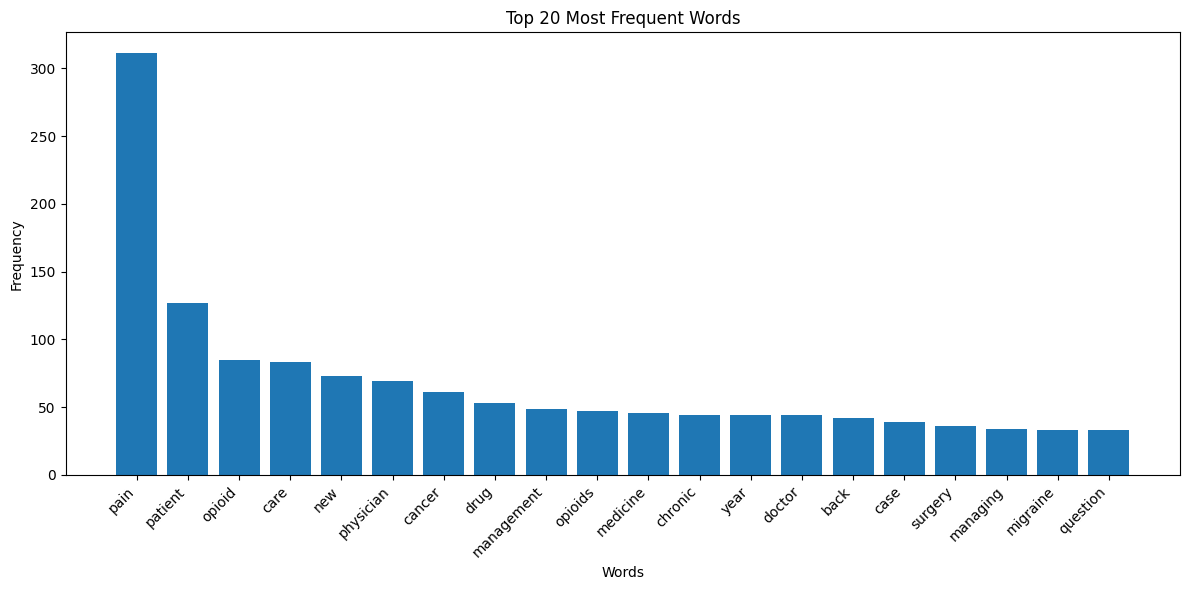


Generating Word Cloud...


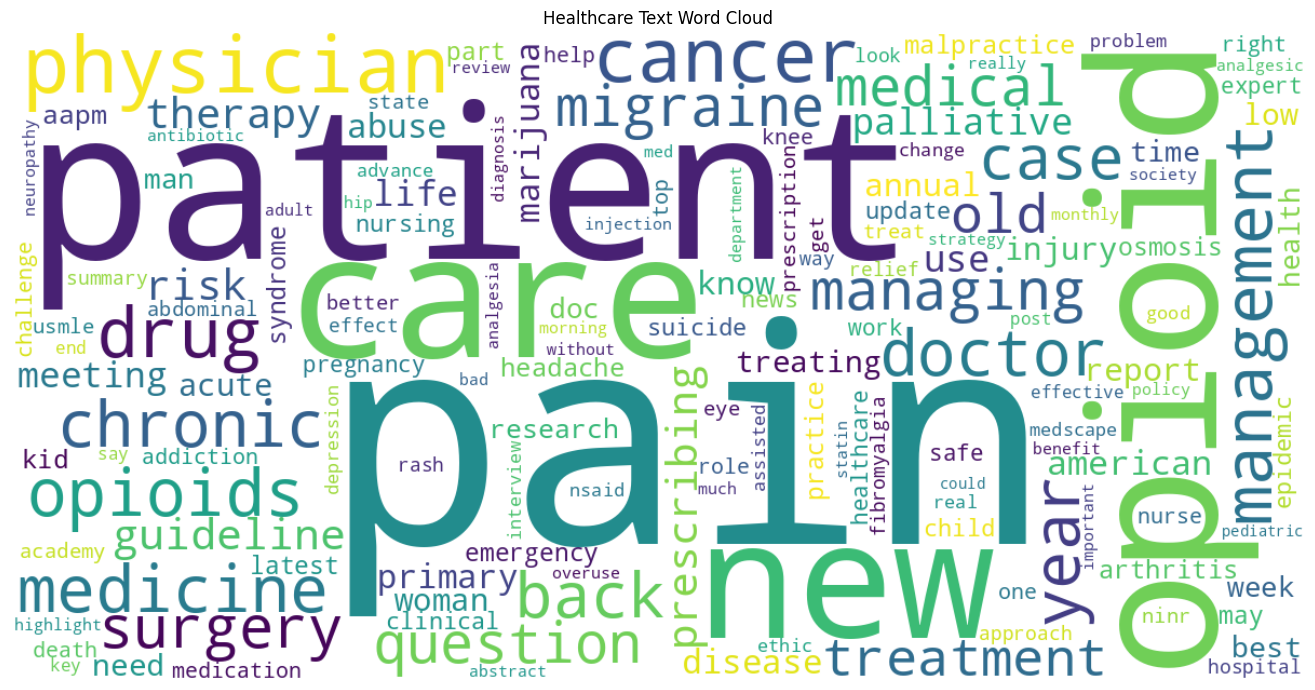

Word cloud saved: /content/healthcare_wordcloud.png

TASK 3: LDA TOPIC MODELING

Dictionary size: 1069
Documents used for LDA: 1607
Corpus and document alignment verified.

LDA Model trained successfully.

Top Words in Each Topic:

Topic 1:
0.038*"new" + 0.025*"pain" + 0.023*"opioid" + 0.022*"medicine" + 0.022*"physician" + 0.015*"guideline" + 0.015*"meeting" + 0.013*"annual" + 0.011*"clinical" + 0.011*"american"

Topic 2:
0.053*"pain" + 0.030*"patient" + 0.026*"year" + 0.019*"question" + 0.019*"opioid" + 0.018*"old" + 0.015*"medical" + 0.014*"marijuana" + 0.013*"managing" + 0.012*"week"

Topic 3:
0.030*"patient" + 0.026*"pain" + 0.024*"cancer" + 0.020*"care" + 0.014*"life" + 0.013*"physician" + 0.012*"opioid" + 0.012*"drug" + 0.012*"management" + 0.012*"treating"

Topic 4:
0.033*"pain" + 0.019*"treatment" + 0.017*"patient" + 0.016*"disease" + 0.012*"doctor" + 0.012*"medication" + 0.011*"injury" + 0.010*"migraine" + 0.010*"cancer" + 0.008*"headache"

Topic 5:
0.069*"pain" + 0.029*"care


Document alignment verified successfully.

LDA Results — First 20 Documents:


,Original_Row_Index,Cleaned_Text,Dominant_Topic,Topic_Probability,Topic_Distribution
0,0,monthly summary nursing research,3,0.9039,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."
1,1,report annual meeting aacpdm,1,0.8744,"{'Topic_1': np.float32(0.8744), 'Topic_2': np...."
2,2,ninr september,3,0.8287,"{'Topic_1': np.float32(0.0419), 'Topic_2': np...."
3,3,monthly summary nursing research,3,0.9039,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."
4,4,monthly summary nursing research march,3,0.9212,"{'Topic_1': np.float32(0.0193), 'Topic_2': np...."
5,5,pitfall opioids chronic nonmalignant pain,5,0.9209,"{'Topic_1': np.float32(0.0193), 'Topic_2': np...."
6,6,case could guillain barre syndrome,4,0.4792,"{'Topic_1': np.float32(0.0301), 'Topic_2': np...."
7,7,medline abstract chronic nonmalignant back pain,5,0.7675,"{'Topic_1': np.float32(0.1818), 'Topic_2': np...."
8,8,october november reefer madness,4,0.8217,"{'Topic_1': np.float32(0.0419), 'Topic_2': np...."
9,9,pain year old man,2,0.9044,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."



LDA results saved: /content/healthcare_lda_results.csv


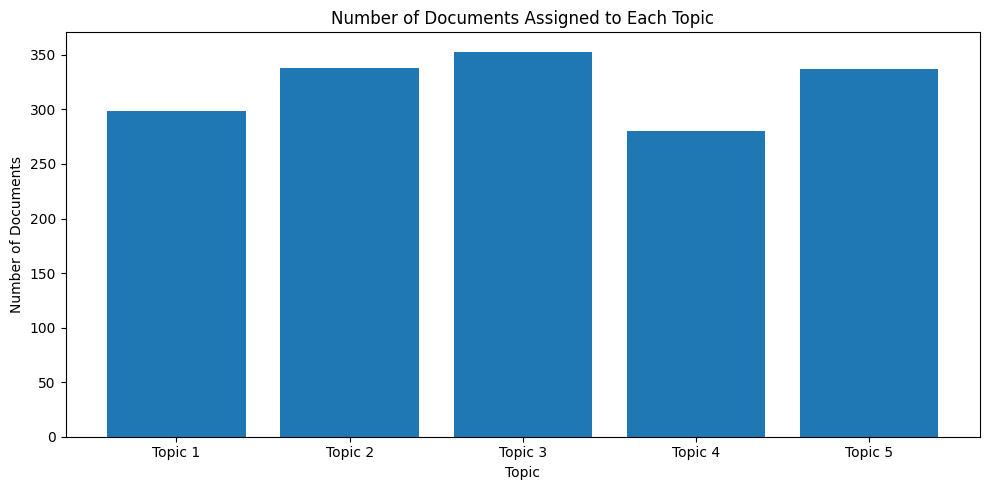


ALL TASKS COMPLETED SUCCESSFULLY

Generated Files:
✓ healthcare_word_frequency.csv
✓ healthcare_wordcloud.png
✓ healthcare_lda_visualization.html
✓ healthcare_lda_results.csv

Word Frequency Results:


,Word,Frequency
0,pain,311
1,patient,127
2,opioid,85
3,care,83
4,new,73
5,physician,69
6,cancer,61
7,drug,53
8,management,49
9,opioids,47



LDA Results Preview:


,Original_Row_Index,Cleaned_Text,Dominant_Topic,Topic_Probability,Topic_Distribution
0,0,monthly summary nursing research,3,0.9039,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."
1,1,report annual meeting aacpdm,1,0.8744,"{'Topic_1': np.float32(0.8744), 'Topic_2': np...."
2,2,ninr september,3,0.8287,"{'Topic_1': np.float32(0.0419), 'Topic_2': np...."
3,3,monthly summary nursing research,3,0.9039,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."
4,4,monthly summary nursing research march,3,0.9212,"{'Topic_1': np.float32(0.0193), 'Topic_2': np...."
5,5,pitfall opioids chronic nonmalignant pain,5,0.9209,"{'Topic_1': np.float32(0.0193), 'Topic_2': np...."
6,6,case could guillain barre syndrome,4,0.4792,"{'Topic_1': np.float32(0.0301), 'Topic_2': np...."
7,7,medline abstract chronic nonmalignant back pain,5,0.7675,"{'Topic_1': np.float32(0.1818), 'Topic_2': np...."
8,8,october november reefer madness,4,0.8217,"{'Topic_1': np.float32(0.0419), 'Topic_2': np...."
9,9,pain year old man,2,0.9044,"{'Topic_1': np.float32(0.0235), 'Topic_2': np...."



Coherence Score: 0.4861

Interactive visualization file:
/content/healthcare_lda_visualization.html

Files are saved in /content.


In [9]:
# ============================================================
# TASK 2: EXPLORATORY TEXT ANALYSIS
# TASK 3: LDA TOPIC MODELING
# ============================================================

# 1. SUPPRESS EXCESSIVE WARNINGS AND LOGS
import warnings
import logging

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore", DeprecationWarning)
warnings.simplefilter("ignore", FutureWarning)

logging.getLogger("gensim").setLevel(logging.ERROR)
logging.getLogger("pyLDAvis").setLevel(logging.ERROR)
logging.getLogger("matplotlib").setLevel(logging.ERROR)

print("Warnings suppressed.")

# ============================================================
# 2. INSTALL AND IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import ast
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from IPython.display import display, HTML

!pip install -q wordcloud gensim pyLDAvis

from wordcloud import WordCloud
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models

# Set output directory
OUTPUT_DIR = "/content"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 3. CHECK PREPROCESSED DATA
# ============================================================

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' was not found. Run your preprocessing cell first."
    )

if "cleaned_tokens" not in df.columns:
    raise KeyError(
        "Column 'cleaned_tokens' was not found in df. "
        "Run your preprocessing cell first."
    )

print("\nDataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

# ============================================================
# 4. NORMALIZE CLEANED TOKENS
# ============================================================

def normalize_tokens(value):
    """
    Convert a cell containing tokens into a list of lowercase strings.
    Handles lists, tuples, strings and missing values.
    """

    if value is None:
        return []

    if isinstance(value, float) and pd.isna(value):
        return []

    if isinstance(value, (list, tuple)):
        tokens = value

    elif isinstance(value, str):
        text = value.strip()

        if not text:
            return []

        # Handle strings that look like Python lists
        if text.startswith("[") and text.endswith("]"):
            try:
                parsed = ast.literal_eval(text)

                if isinstance(parsed, (list, tuple)):
                    tokens = parsed
                else:
                    tokens = text.split()

            except (ValueError, SyntaxError):
                tokens = text.split()
        else:
            tokens = text.split()

    else:
        return []

    return [
        str(token).strip().lower()
        for token in tokens
        if str(token).strip()
    ]


processed_documents = df["cleaned_tokens"].apply(normalize_tokens).tolist()

# Retain the original DataFrame row indices for later alignment.
original_row_indices = df.index.tolist()

# ============================================================
# TASK 2: EXPLORATORY TEXT ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 5. WORD FREQUENCY ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TASK 2: EXPLORATORY TEXT ANALYSIS")
print("=" * 60)

all_words = [
    word
    for document in processed_documents
    for word in document
]

if not all_words:
    raise ValueError(
        "No words were found in cleaned_tokens. "
        "Check your preprocessing output."
    )

word_counts = Counter(all_words)

# Get the 20 most frequent words
top_words = word_counts.most_common(20)

word_frequency_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

print("\nTop 20 Most Frequent Words:")
display(word_frequency_df)

# Save word frequency results
frequency_path = os.path.join(
    OUTPUT_DIR,
    "healthcare_word_frequency.csv"
)

word_frequency_df.to_csv(frequency_path, index=False)

# ------------------------------------------------------------
# 6. VISUALIZE TOP 20 WORDS
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    word_frequency_df["Word"],
    word_frequency_df["Frequency"]
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. GENERATE WORD CLOUD
# ------------------------------------------------------------

print("\nGenerating Word Cloud...")

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150
).generate_from_frequencies(word_counts)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Healthcare Text Word Cloud")
plt.tight_layout()
plt.show()

# Save the word cloud
wordcloud_path = os.path.join(
    OUTPUT_DIR,
    "healthcare_wordcloud.png"
)

wordcloud.to_file(wordcloud_path)

print("Word cloud saved:", wordcloud_path)

# ============================================================
# TASK 3: LDA TOPIC MODELING
# ============================================================

print("\n" + "=" * 60)
print("TASK 3: LDA TOPIC MODELING")
print("=" * 60)

# ------------------------------------------------------------
# 8. CREATE DICTIONARY AND BAG-OF-WORDS CORPUS
# ------------------------------------------------------------

# Keep only documents containing at least one token.
nonempty_documents = []
nonempty_row_indices = []

for tokens, row_index in zip(
    processed_documents,
    original_row_indices
):
    if tokens:
        nonempty_documents.append(tokens)
        nonempty_row_indices.append(row_index)

if not nonempty_documents:
    raise ValueError(
        "No non-empty documents are available for LDA."
    )

# Build the dictionary
dictionary = corpora.Dictionary(nonempty_documents)

# Remove very rare and extremely common terms
dictionary.filter_extremes(
    no_below=2,
    no_above=0.90
)

if len(dictionary) == 0:
    raise ValueError(
        "The dictionary is empty after filtering. "
        "Try no_below=1 or review the cleaned tokens."
    )

# IMPORTANT:
# Keep documents, BOW vectors and row indices aligned.
lda_documents = []
corpus = []
lda_document_rows = []

for tokens, row_index in zip(
    nonempty_documents,
    nonempty_row_indices
):
    bow = dictionary.doc2bow(tokens)

    # Skip documents with no words remaining after filtering.
    if bow:
        lda_documents.append(tokens)
        corpus.append(bow)
        lda_document_rows.append(row_index)

if not corpus:
    raise ValueError(
        "The corpus is empty after dictionary filtering."
    )

assert len(lda_documents) == len(corpus) == len(lda_document_rows)

print("\nDictionary size:", len(dictionary))
print("Documents used for LDA:", len(corpus))
print("Corpus and document alignment verified.")

# ------------------------------------------------------------
# 9. TRAIN THE LDA MODEL
# ------------------------------------------------------------

NUM_TOPICS = 5

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    random_state=42,
    passes=10,
    iterations=100,
    alpha="auto",
    eta="auto",
    per_word_topics=True
)

print("\nLDA Model trained successfully.")

# ------------------------------------------------------------
# 10. DISPLAY TOPIC WORDS
# ------------------------------------------------------------

print("\nTop Words in Each Topic:\n")

for topic_id, topic_words in lda_model.print_topics(
    num_topics=NUM_TOPICS,
    num_words=10
):
    print(f"Topic {topic_id + 1}:")
    print(topic_words)
    print()

# ------------------------------------------------------------
# 11. CALCULATE COHERENCE SCORE
# ------------------------------------------------------------

coherence_model = CoherenceModel(
    model=lda_model,
    texts=lda_documents,
    dictionary=dictionary,
    coherence="c_v"
)

coherence_score = coherence_model.get_coherence()

print("LDA Coherence Score:", round(coherence_score, 4))

# ------------------------------------------------------------
# 12. GENERATE INTERACTIVE LDA VISUALIZATION
# ------------------------------------------------------------

print("\nGenerating interactive LDA visualization...")

lda_visualization = pyLDAvis.gensim_models.prepare(
    lda_model,
    corpus,
    dictionary,
    sort_topics=False
)

# Save HTML visualization
visualization_path = os.path.join(
    OUTPUT_DIR,
    "healthcare_lda_visualization.html"
)

pyLDAvis.save_html(
    lda_visualization,
    visualization_path
)

print("Interactive visualization saved:", visualization_path)

# Display interactive visualization in Colab
display(HTML(lda_visualization_to_html := pyLDAvis.prepared_data_to_html(
    lda_visualization
)))

# ------------------------------------------------------------
# 13. FIND THE DOMINANT TOPIC FOR EACH DOCUMENT
# ------------------------------------------------------------

dominant_topics = []
topic_probabilities = []
topic_distributions = []

for bow in corpus:

    topic_distribution = lda_model.get_document_topics(
        bow,
        minimum_probability=0
    )

    # Convert topic probabilities into a dictionary
    topic_probability_dict = dict(topic_distribution)

    # Find the topic with the highest probability
    dominant_topic, dominant_probability = max(
        topic_probability_dict.items(),
        key=lambda item: item[1]
    )

    dominant_topics.append(dominant_topic + 1)
    topic_probabilities.append(dominant_probability)

    topic_distributions.append(
        {
            f"Topic_{topic_id + 1}": round(probability, 4)
            for topic_id, probability in topic_distribution
        }
    )

# Verify that every result has a matching document
assert (
    len(lda_documents)
    == len(corpus)
    == len(lda_document_rows)
    == len(dominant_topics)
    == len(topic_probabilities)
    == len(topic_distributions)
)

print("\nDocument alignment verified successfully.")

# ------------------------------------------------------------
# 14. CREATE LDA RESULTS DATAFRAME
# ------------------------------------------------------------

# This list uses the same filtered documents as the corpus.
cleaned_texts = [
    " ".join(tokens)
    for tokens in lda_documents
]

lda_results_df = pd.DataFrame({
    "Original_Row_Index": lda_document_rows,
    "Cleaned_Text": cleaned_texts,
    "Dominant_Topic": dominant_topics,
    "Topic_Probability": [
        round(probability, 4)
        for probability in topic_probabilities
    ],
    "Topic_Distribution": [
        str(distribution)
        for distribution in topic_distributions
    ]
})

print("\nLDA Results — First 20 Documents:")
display(lda_results_df.head(20))

# Save LDA results
lda_results_path = os.path.join(
    OUTPUT_DIR,
    "healthcare_lda_results.csv"
)

lda_results_df.to_csv(
    lda_results_path,
    index=False
)

print("\nLDA results saved:", lda_results_path)

# ------------------------------------------------------------
# 15. VISUALIZE DOCUMENT COUNTS PER TOPIC
# ------------------------------------------------------------

topic_counts = (
    lda_results_df["Dominant_Topic"]
    .value_counts()
    .sort_index()
)

# Include topics with zero assigned documents
topic_counts = topic_counts.reindex(
    range(1, NUM_TOPICS + 1),
    fill_value=0
)

plt.figure(figsize=(10, 5))

plt.bar(
    [f"Topic {topic_id}" for topic_id in topic_counts.index],
    topic_counts.values
)

plt.title("Number of Documents Assigned to Each Topic")
plt.xlabel("Topic")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. DISPLAY FINAL OUTPUT FILES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ALL TASKS COMPLETED SUCCESSFULLY")
print("=" * 60)

print("\nGenerated Files:")

for filename in [
    "healthcare_word_frequency.csv",
    "healthcare_wordcloud.png",
    "healthcare_lda_visualization.html",
    "healthcare_lda_results.csv"
]:
    filepath = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(filepath):
        print(f"✓ {filename}")
    else:
        print(f"✗ {filename} was not generated.")

print("\nWord Frequency Results:")
display(word_frequency_df)

print("\nLDA Results Preview:")
display(lda_results_df.head(10))

print("\nCoherence Score:", round(coherence_score, 4))

print("\nInteractive visualization file:")
print(visualization_path)

print("\nFiles are saved in /content.")